# SE match estimation: uniform prior

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    Δ = lambda n_len: int(n_len / 10)
    n_small = 50
    Delta_n_small = int(Δ(n) * n_small/n)
    p_l = None
    Lmin = L
    Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π= pi
    π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix

    # pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # pi = np.zeros((L, n))
    # for l__ in range(L):
    #     for i__ in range(n):
    #         pi[l__, i__] = pi_i_l(L, l__ + 1, i__ + 1)
    # π = pi
    # π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix


    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T
    # ε = nprandom.randn(n) * noise_std
    ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise. df > 2 has finite variance.
    B̃ = np.sqrt(δ) * B̃ # Scale B̃ by sqrt(delta) here since we vary delta, see the definition of B̃ outside of loop. 
    Θ = X @ B̃
    y_mapped_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))
    y = y_mapped_fn(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
    b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model)
    κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
    print("-"*60)
    print("b, ν̃, κ̃ for δ=", δ, ":", b, ν̃, κ̃, ", trial : ", j+1)
    print("-"*60)

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            Θ̂_theory = np.zeros((n, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-LS':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :])
                    empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=4096, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-LS':
                G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                G_sample_n = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                Z = nprandom.multivariate_normal(np.zeros((L, )), ρ, size=(n,))
                y_theory = y_mapped_fn(Z, C_true, ε) 
                M_prime = jax.grad(M, argnums=0)
                M_double_prime = jax.grad(M_prime, argnums=0)
                for ℓ_ in range(L):
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                    
                    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :])
                    prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                    Θ̂_theory[:, ℓ_] = prox_mapped(Z @ ν̃[:, ℓ_] + G_sample_n[:, ℓ_], b[ℓ_], sample_weight, y_theory)

                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=4096, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 700 # at least 500 is needed for stable results
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.2)

δ_list = np.arange(2.0, 6.1, 1.0)
num_trials = 10 # Increased for better statistics
fractional_chgpt_locations = np.array([0.4, 0.7]) # Single changepoint at 0.7n

n_jobs = 1 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Sample the signal outside
κ = 1.0
B̃_cov = κ**2 * np.eye(L) # Omit the δ term here, multiply it inside of the trial loop since we vary δ
# Add some correlation between signals for L > 1
r_B = 0.25
if L > 1:
    for ll in range(L):
        for mm in range(L):
            if ll != mm:
                B̃_cov[ll, mm] = r_B**(abs(ll - mm)) * κ**2
signal_prior = GaussianSignal(B̃_cov)
B̃ = signal_prior.sample(p)

def sample_corr(p, df=10, seed=None):
    """Sample a random correlation matrix using the Haar measure."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
    λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
    B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
    D = np.sqrt(np.diag(B))
    return B / np.outer(D, D)

Sigma = sample_corr(p, df=10, seed=random_seed) 

# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
# r_s = 0.1
# AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
# Sigma = AR1
# Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-LS', 'label': r'\textbf{ERM-LS}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-LS', 'label': r'\textbf{Theory-LS}', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs,
            B̃=B̃
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=0) # Changed axis to 0 for signal-specific data
    p25 = np.nanpercentile(data, 25, axis=0)
    p75 = np.nanpercentile(data, 75, axis=0)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication_per_signal(L):
    """
    Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    # Select data for the current signal l_idx
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    errors = get_asymmetric_errors(data_l)
                    ax.errorbar(δ_list, means, yerr=errors,
                                 label=f"{method_obj['label']} ($\\ell={l_idx+1}$)",
                                 marker=plot_markers[i], ls=plot_linestyles[i],
                                 color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], # Use a colormap for signals
                                 capsize=4, capthick=2, markersize=8,
                                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before (average across trials)
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors,
                             label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i],
                             color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                             linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            
        if ylim:
            ax.set_ylim(ylim)
        else:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication_per_signal(L):
    """
    Plots with confidence bands, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            
            if metric_key in ['corr', 'mse']:
                for l_idx in range(L):
                    data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                    if np.all(np.isnan(data_l)):
                        main_logger.warning(f"No successful trials for {method_name} (signal {l_idx+1}, {metric_key}). Skipping plot.")
                        continue
                    means = np.nanmean(data_l, axis=1)
                    p10 = np.nanpercentile(data_l, 10, axis=1)
                    p90 = np.nanpercentile(data_l, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)

                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    ax.fill_between(δ_list, p10, p90, color=current_color,
                                     alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=current_color, linewidth=4,
                             marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)", zorder=3,
                             markeredgewidth=2, markeredgecolor='white')
            else:
                # For other metrics, continue as before
                data = results[f'{metric_key}_{method_name}']
                if np.all(np.isnan(data)):
                    main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                    continue
                means = np.nanmean(data, axis=1)
                p10 = np.nanpercentile(data, 10, axis=1)
                p90 = np.nanpercentile(data, 90, axis=1)
                p10 = np.minimum(p10, means)
                p90 = np.maximum(p90, means)

                ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                                 alpha=0.15, zorder=1)
                ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                         marker='o', markersize=9, label=method_obj['label'], zorder=3,
                         markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=(len(methods_to_evaluate) * L) + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0),
               fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication_per_signal(L):
    """
    Creates box plots, showing each signal (l) separately for corr and mse.
    """
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}',
                 fontsize=20, y=0.98)

    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics_to_plot = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics_to_plot):
        ax = axs[ax_idx]
        
        # Adjusted spacing for per-signal plots
        spacing = (len(methods_to_evaluate) * L) + 1 
        if metric_key not in ['corr', 'mse']:
            spacing = len(methods_to_evaluate) + 1 # Revert spacing for non-signal-specific plots

        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                        valid_data = data_l[~np.isnan(data_l)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            # Position calculation needs to account for both method and signal
                            position = delta_idx * spacing + (method_idx * L + l_idx) 
                            box_positions.append(position)
                            box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                        else:
                            main_logger.warning(f"No valid data for {method_name} (signal {l_idx+1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")
                else:
                    # For other metrics, use the original logic
                    data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                    valid_data = data[~np.isnan(data)]
                    if len(valid_data) > 0:
                        box_data.append(valid_data)
                        box_positions.append(delta_idx * spacing + method_idx)
                        box_colors.append(plot_colors[method_idx])
                    else:
                        main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        if metric_key in ['corr', 'mse']:
            # Adjusted xticks for per-signal plots
            delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
        else:
            delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]

        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = []
        if metric_key in ['corr', 'mse']:
            # Create legend elements for each method and each signal
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                for l_idx in range(L):
                    current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                    legend_elements.append(plt.Rectangle((0,0),1,1, facecolor=current_color,
                                                         alpha=0.8, edgecolor='black',
                                                         linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx+1}$)" ))
        else:
            # Original legend elements for other metrics
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=plot_labels[i])
                                             for i in range(len(methods_to_evaluate))]

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=10,
                  frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L-1 if metric_key in ['corr', 'mse'] else 0) ) # Adjust ncol based on L
        
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Execute publication-ready plotting options
# main_logger.info("Generating plots...")
# print("1. Asymmetric error bars (publication style) per signal...")
# plot_with_asymmetric_errors_publication_per_signal(L)
# print("2. Confidence bands (publication style) per signal...")
# plot_with_confidence_bands_publication_per_signal(L)
# print("3. Box plots (publication style) per signal...")
# plot_with_boxplots_publication_per_signal(L)
# print("4. Enhanced changepoint histograms (publication style)...")
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
# plotting_time = time.time() - plotting_start_time
# main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_unif_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

10:40:36 - Starting WERM Simulation with parallel execution and enhanced logging
10:40:36 - ================================================================================
10:40:36 - Simulation Parameters:
10:40:36 -  p (features): 700
10:40:36 -  L (signals): 3
10:40:36 -  noise_std: 0.4472135954999579
10:40:36 -  δ_list: [2. 3. 4. 5. 6.]
10:40:36 -  num_trials: 10
10:40:36 -  fractional_chgpt_locations: [0.4 0.7]
10:40:36 -  n_jobs: 1
10:40:36 -  Loss function: Least Squares
10:40:36 -  Methods to evaluate: ['ERM-LS', 'Theory-LS']
10:40:36 -  Total tasks: 50
10:40:36 - ================================================================================
10:40:36 - Starting 50 simulation trials
10:40:36 - Using 1 CPU cores
10:40:36 - Estimated total time: 16.7 minutes
10:40:36 - Estimated completion: 2025-07-09 10:57:16
10:40:36 - ================================================================================


Running simulation trials:   0%|                                             | 0/50 [00:00<?, ?it/s]

\Delta: 5, n: 50, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/528 [00:00<?, ?it/s]

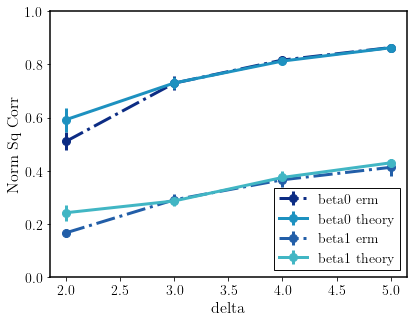

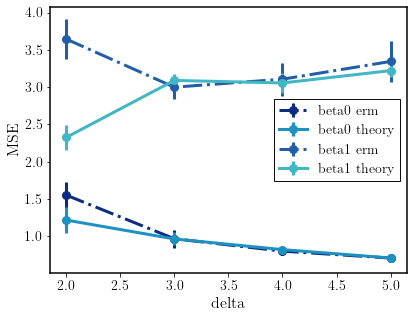

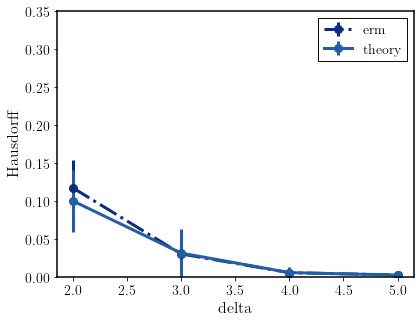

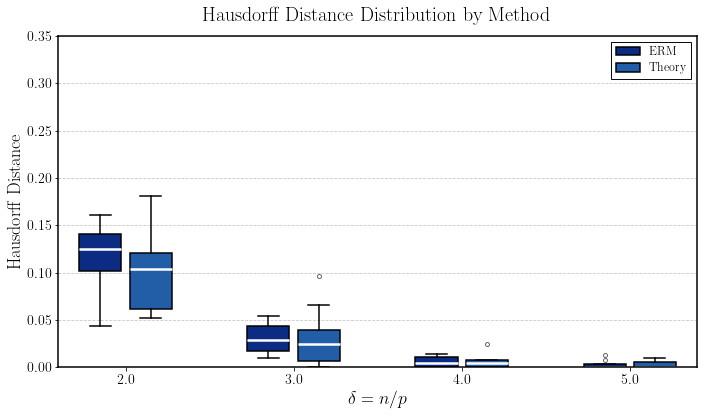

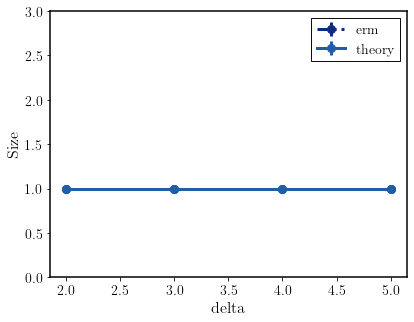

In [8]:
PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
erm_corr_arr = results['corr_ERM-LS']
theory_corr_arr = results['corr_Theory-LS']
erm_MSE_arr = results['mse_ERM-LS']
theory_MSE_arr = results['mse_Theory-LS']
erm_haus_arr = results['haus_ERM-LS']
theory_haus_arr = results['haus_Theory-LS']
erm_size_arr = results['size_ERM-LS']
theory_size_arr = results['size_Theory-LS']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("delta")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="beta" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("delta")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("delta")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Display boxplots for Hausdorff
plt.figure(figsize=(10, 6))
box_data_erm = [erm_haus_arr[i, ~np.isnan(erm_haus_arr[i, :])] for i in range(len(δ_list))]
box_data_theory = [theory_haus_arr[i, ~np.isnan(theory_haus_arr[i, :])] for i in range(len(δ_list))]
positions_erm = np.array(range(len(δ_list))) * 2.0 - 0.3
positions_theory = np.array(range(len(δ_list))) * 2 + 0.3
bp_erm = plt.boxplot(box_data_erm, positions=positions_erm, widths=0.5,
                     patch_artist=True, boxprops=dict(facecolor=PAL[0], edgecolor='black', linewidth=1.5),
                     medianprops=dict(color='white', linewidth=2.5),
                     whiskerprops=dict(linewidth=1.5),
                     capprops=dict(linewidth=1.5),
                     flierprops=dict(marker='o', markersize=4, alpha=0.6))
bp_theory = plt.boxplot(box_data_theory, positions=positions_theory, widths=0.5,
                        patch_artist=True, boxprops=dict(facecolor=PAL[1], edgecolor='black', linewidth=1.5),
                        medianprops=dict(color='white', linewidth=2.5),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5),
                        flierprops=dict(marker='o', markersize=4, alpha=0.6))
plt.xticks(np.array(range(len(δ_list))) * 2, [f'{d:.1f}' for d in δ_list])
plt.xlabel(r'$\delta = n/p$', fontsize=18)
plt.ylabel('Hausdorff Distance', fontsize=18)
plt.title('Hausdorff Distance Distribution by Method', fontsize=20, pad=15)
plt.legend([bp_erm["boxes"][0], bp_theory["boxes"][0]], ['ERM', 'Theory'], loc='upper right', fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
plt.ylim((0, 0.35))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("delta")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# SE match estimation: switching prior

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)
jax.random.PRNGKey(random_seed) # Set JAX random seed as well

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    # Create logs directory if it doesn't exist
    import os
    log_dir = 'logs'
    if not os.path.exists(log_dir):
        os.makedirs(log_dir)

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)
    main_logger.handlers = [] # Clear existing handlers

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/WERM_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)
    progress_logger.handlers = [] # Clear existing handlers

    progress_handler = logging.FileHandler('logs/WERM_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        # Log delta-specific progress less frequently to avoid excessive logging
        if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params # i: delta_list index, δ: current delta value, j: trial number
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n_len: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0.

    # --- Preliminaries (from original code) ---
    Δ = lambda n_len: int(n_len / 5)
    n_small = 50
    Delta_n_small = int(Δ(n) * n_small/n)
    p_l = None
    Lmin = L
    Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
    π= pi
    π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix
    
    # pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # pi = np.zeros((L, n))
    # for l__ in range(L):
    #     for i__ in range(n):
    #         pi[l__, i__] = pi_i_l(L, l__ + 1, i__ + 1)
    # π = pi
    # π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix

    # Switching signal prior: add first and third rows of π
    pi_new = np.zeros((L, n))
    pi_new[0, :] = π[0, :] + π[2, :]  # Combine first and third rows
    pi_new[1, :] = π[1, :]  # Keep second row unchanged
    pi_new[2, :] = π[0, :] + π[2, :]  # Repeat for third row
    # Normalize the new π
    pi_new = pi_new / np.sum(pi_new, axis=1, keepdims=True)
    π = pi_new

    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L)
    # Make the first and third signals identical
    B̃_cov[0, 0] = κ**2 * δ 
    B̃_cov[2, 2] = κ**2 * δ
    B̃_cov[0, 2] = κ**2 * δ  # Covariance between first and third signals
    B̃_cov[2, 0] = κ**2 * δ  # Covariance between first and third signals
    B̃_cov = B̃_cov + 1e-12 * jnp.eye(L)  # Add small noise to ensure positive definiteness
    signal_prior = GaussianSignal(B̃_cov)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = nprandom.randn(n) * noise_std
    Θ = X @ B̃
    y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    # Compute fixed point solution once per delta for theoretical comparison
    b, ν̃, κ̃ = fp.general_fp(M, (1/δ) * (1/p) * (B̃.T @ B̃), δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model)
    κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))

    # --- Run Estimators for all configured methods ---
    for method_name, method_func_info in method_configs.items():
        try:
            method_start = time.time()
            current_B̂ = np.zeros((p, L))
            current_corr_list = []
            current_mse_list = []
            current_chgpt_loc = np.array([])

            if method_name == 'ERM-LS':
                for ℓ_ in range(L):
                    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :])
                    empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
                    res = scipy.optimize.minimize(empirical_risk, 0.1*np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                    β̂ = res.x
                    current_B̂[:, ℓ_] = β̂
                    current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for ERM
                opt_chgpt_loc_erm, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=1024, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_erm

            elif method_name == 'Theory-LS':
                for ℓ_ in range(L):
                    G_sample = nprandom.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                    β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]
                    current_B̂[:, ℓ_] = β̂_theory
                    current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))
                    current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
                # Determine changepoints for Theory
                opt_chgpt_loc_theory, _ = WERM.gof.chgpt_gof_bf_mem_eff(
                    M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False,
                    γ=0, batch_size=1024, gof_opt_output=True
                )
                current_chgpt_loc = opt_chgpt_loc_theory
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
            trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
            trial_results[f'haus_{method_name}'] = (1/n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n)))
            trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
            trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}", exc_info=True)
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
            trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting WERM Simulation with parallel execution and enhanced logging")
main_logger.info("=" * 80)

# Simulation Parameters
p = 500
L = 3 # num signals. L-1 changepoints
noise_std = np.sqrt(0.3)

δ_list = np.arange(1.0, 5.0, 1.0)
num_trials = 30 # Increased for better statistics
fractional_chgpt_locations = np.array([0.45, 0.75]) # Single changepoint at 0.6n

n_jobs = 10 # Use all available CPU cores. Set to 1 for no parallelization.
# n_jobs = 1 # Use all available CPU cores. Set to 1 for no parallelization.

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'ERM-LS', 'label': r'\textbf{ERM-LS}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'Theory-LS', 'label': r'\textbf{Theory-LS}', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Loss function: Least Squares")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = [] # Store (delta_idx, chgpts_array) for histogram plotting


# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 80)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

# Rough estimate for total time, adjust based on typical single trial runtime
single_trial_estimate = 20.0 # seconds, adjust this based on observation
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 80)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100, leave=True)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 80)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 80)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}", exc_info=True)
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
            results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}'])) # Always append, even if empty

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
        std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
        avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
        std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}")
        main_logger.info(f" {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


01:20:05 - Starting WERM Simulation with parallel execution and enhanced logging
01:20:05 - ================================================================================
01:20:05 - Simulation Parameters:
01:20:05 -  p (features): 500
01:20:05 -  L (signals): 3
01:20:05 -  noise_std: 0.5477225575051661
01:20:05 -  δ_list: [1. 2. 3. 4.]
01:20:05 -  num_trials: 30
01:20:05 -  fractional_chgpt_locations: [0.45 0.75]
01:20:05 -  n_jobs: 10
01:20:05 -  Loss function: Least Squares
01:20:05 -  Methods to evaluate: ['ERM-LS', 'Theory-LS']
01:20:05 -  Total tasks: 120
01:20:05 - ================================================================================
01:20:05 - Starting 120 simulation trials
01:20:05 - Using 10 CPU cores
01:20:05 - Estimated total time: 4.0 minutes
01:20:05 - Estimated completion: 2025-07-09 01:24:05
01:20:05 - ================================================================================


Running simulation trials:   0%|                                            | 0/120 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
A

Optimization Results: all =       message: `ftol` termination condition is satisfied.
     success: True
      status: 2
         fun: [-7.946e-03 -3.357e-01 ... -2.333e-09  1.433e-09]
           x: [ 5.995e+04  4.897e+06 ... -1.873e+00  1.204e+01]
        cost: 0.05638731792014821
         jac: [[ 1.303e-07  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  1.327e-08 ...  0.000e+00  0.000e+00]
               ...
               [ 0.000e+00 -3.601e-08 ...  4.019e-01 -6.447e-04]
               [ 0.000e+00  0.000e+00 ... -2.546e-01 -3.081e-02]]
        grad: [-1.035e-09 -4.455e-09 ... -2.347e-09 -2.166e-10]
  optimality: 2.5767680490041852e-08
 active_mask: [0 0 ... 0 0]
        nfev: 50
        njev: 38 success =  True , message =  `ftol` termination condition is satisfied.
Starting brute-force search over 79,800 configurations, with L = 3 and k = 2 change points.


Brute-force Search:   0%|          | 0/78 [00:00<?, ?it/s]

... (58 outputs left out)

Search complete. Optimal GoF score: 0.0125
Starting brute-force search over 79,800 configurations, with L = 3 and k = 2 change points.


Brute-force Search:  97%|█████████▋| 76/78 [00:03<00:00, 23.24it/s]

Optimization Results: all =       message: Both `ftol` and `xtol` termination conditions are satisfied.
     success: True
      status: 4
         fun: [-3.370e-03 -3.184e-01 ...  9.113e-08  1.085e-07]
           x: [ 1.428e+05  6.298e+06 ... -1.309e+01  8.688e+01]
        cost: 0.05068701985993071
         jac: [[ 2.344e-08  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  1.155e-08 ...  0.000e+00  0.000e+00]
               ...
               [ 0.000e+00 -6.250e-08 ...  3.527e-01 -1.111e-02]
               [ 0.000e+00  0.000e+00 ... -1.663e+00 -4.402e-01]]
        grad: [-7.681e-11 -3.677e-09 ... -1.050e-07 -2.643e-08]
  optimality: 4.902594175803323e-07
 active_mask: [0 0 ... 0 0]
        nfev: 111
        njev: 83 success =  True , message =  Both `ftol` and `xtol` termination conditions are satisfied.
Starting brute-force search over 79,800 configurations, with L = 3 and k = 2 change points.
Search complete. Optimal GoF score: 0.1618
Starting brute-force search ove

Brute-force Search:   1%|▏         | 1/78 [00:00<00:11,  6.99it/s]

02:07:35 - Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB'] (Paul Tol Vibrant assigned to methods)
02:07:35 - Generating plots...
1. Asymmetric error bars (publication style)...


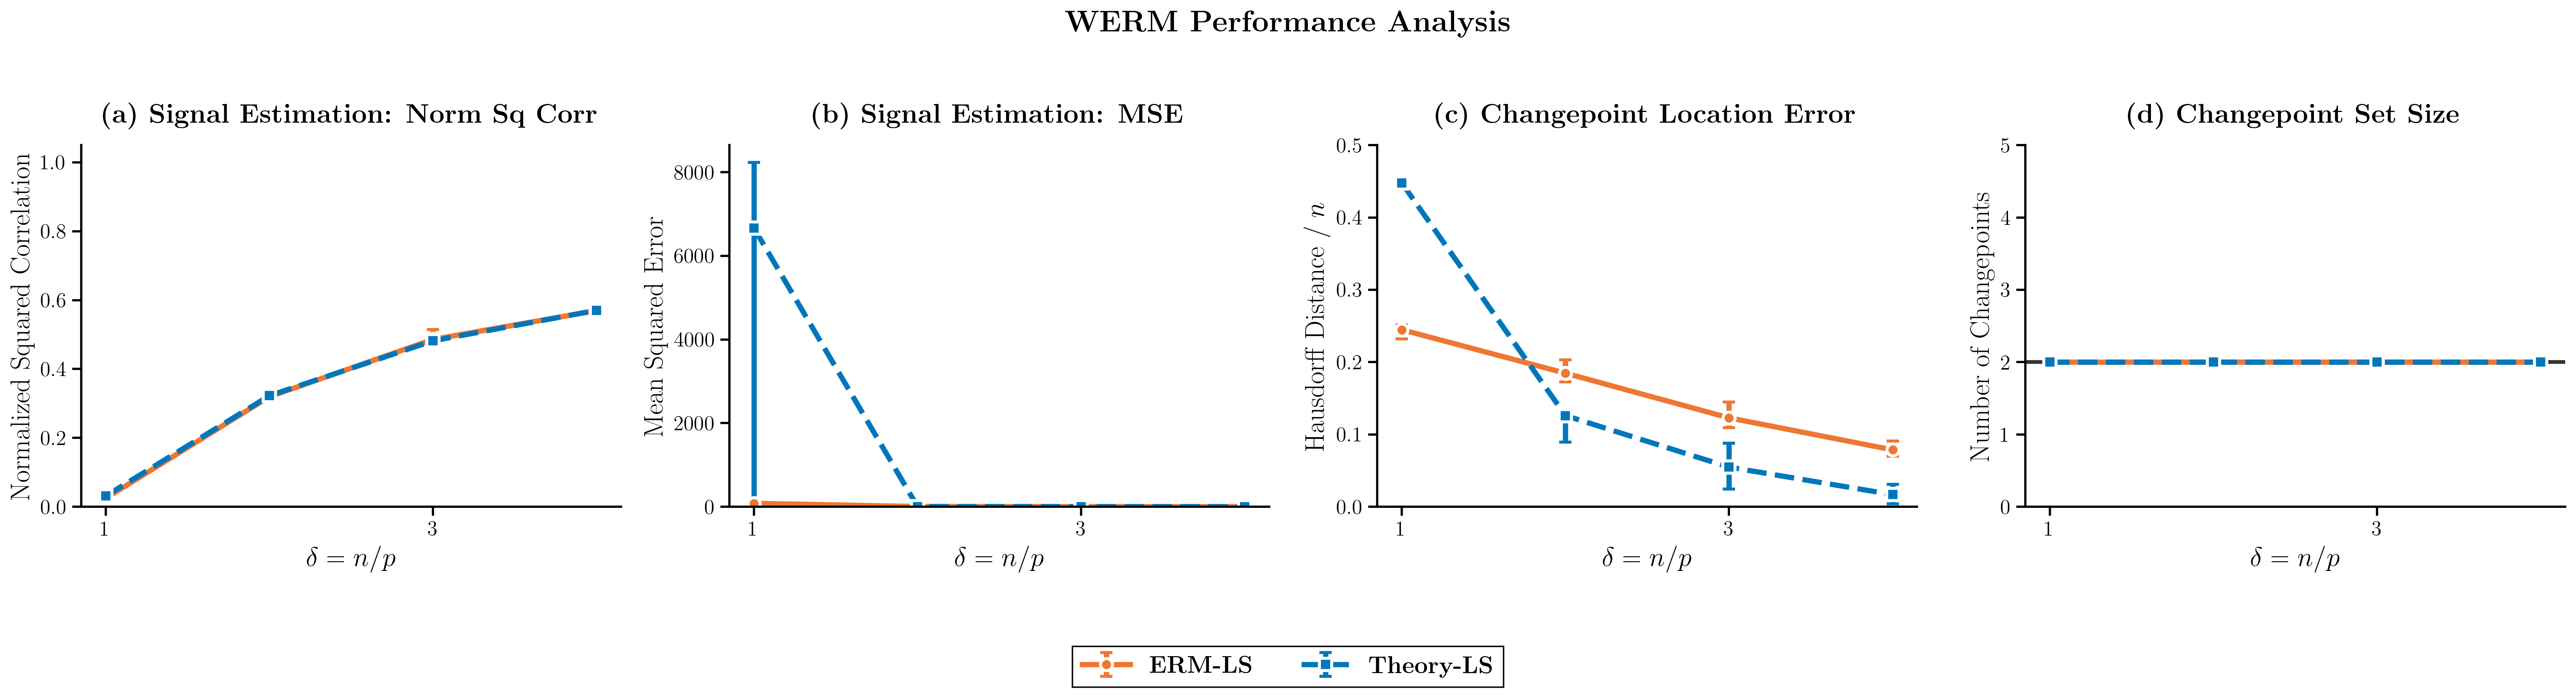

2. Confidence bands (publication style)...


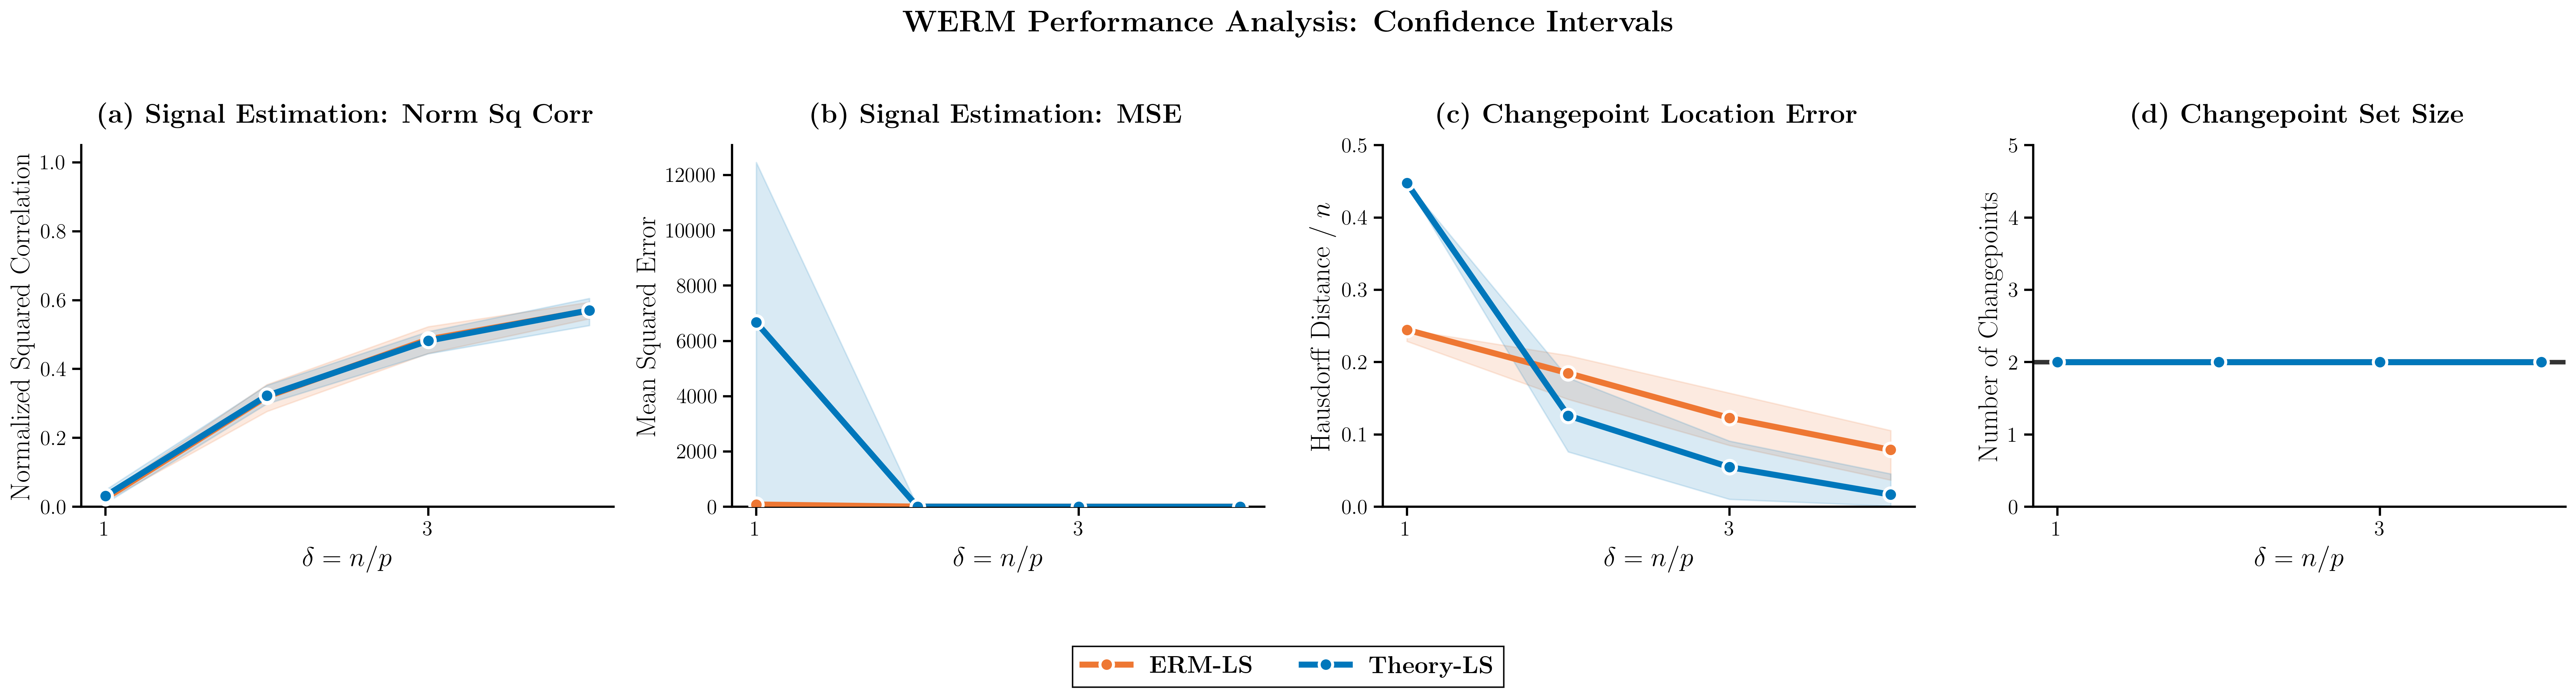

3. Box plots (publication style)...


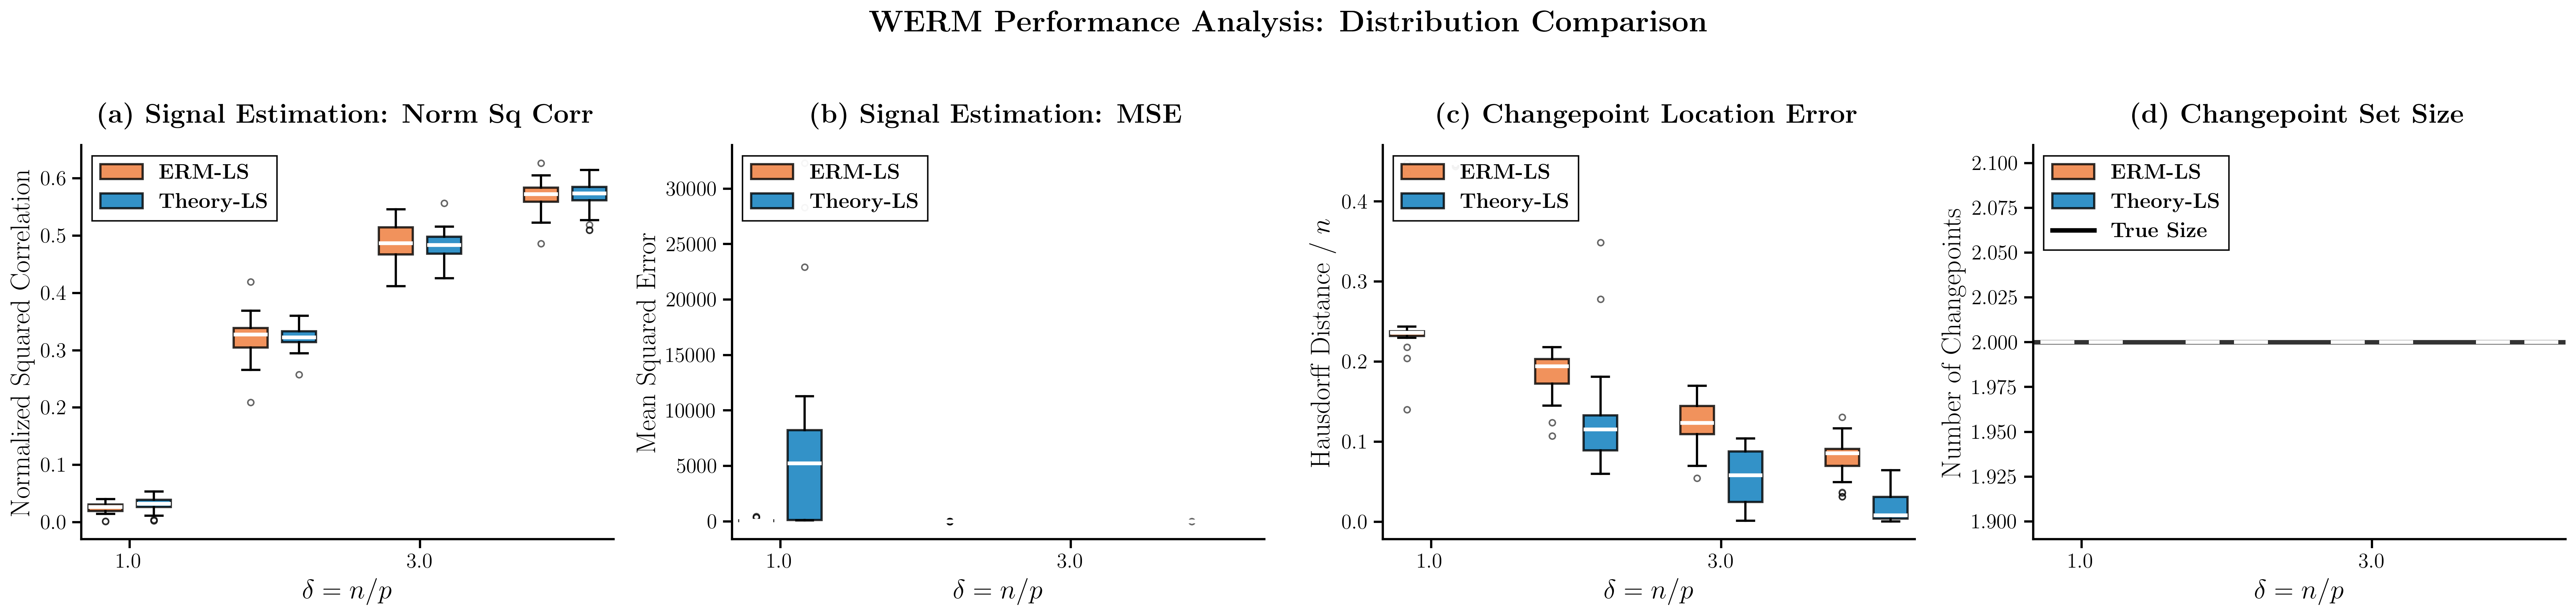

4. Enhanced changepoint histograms (publication style)...


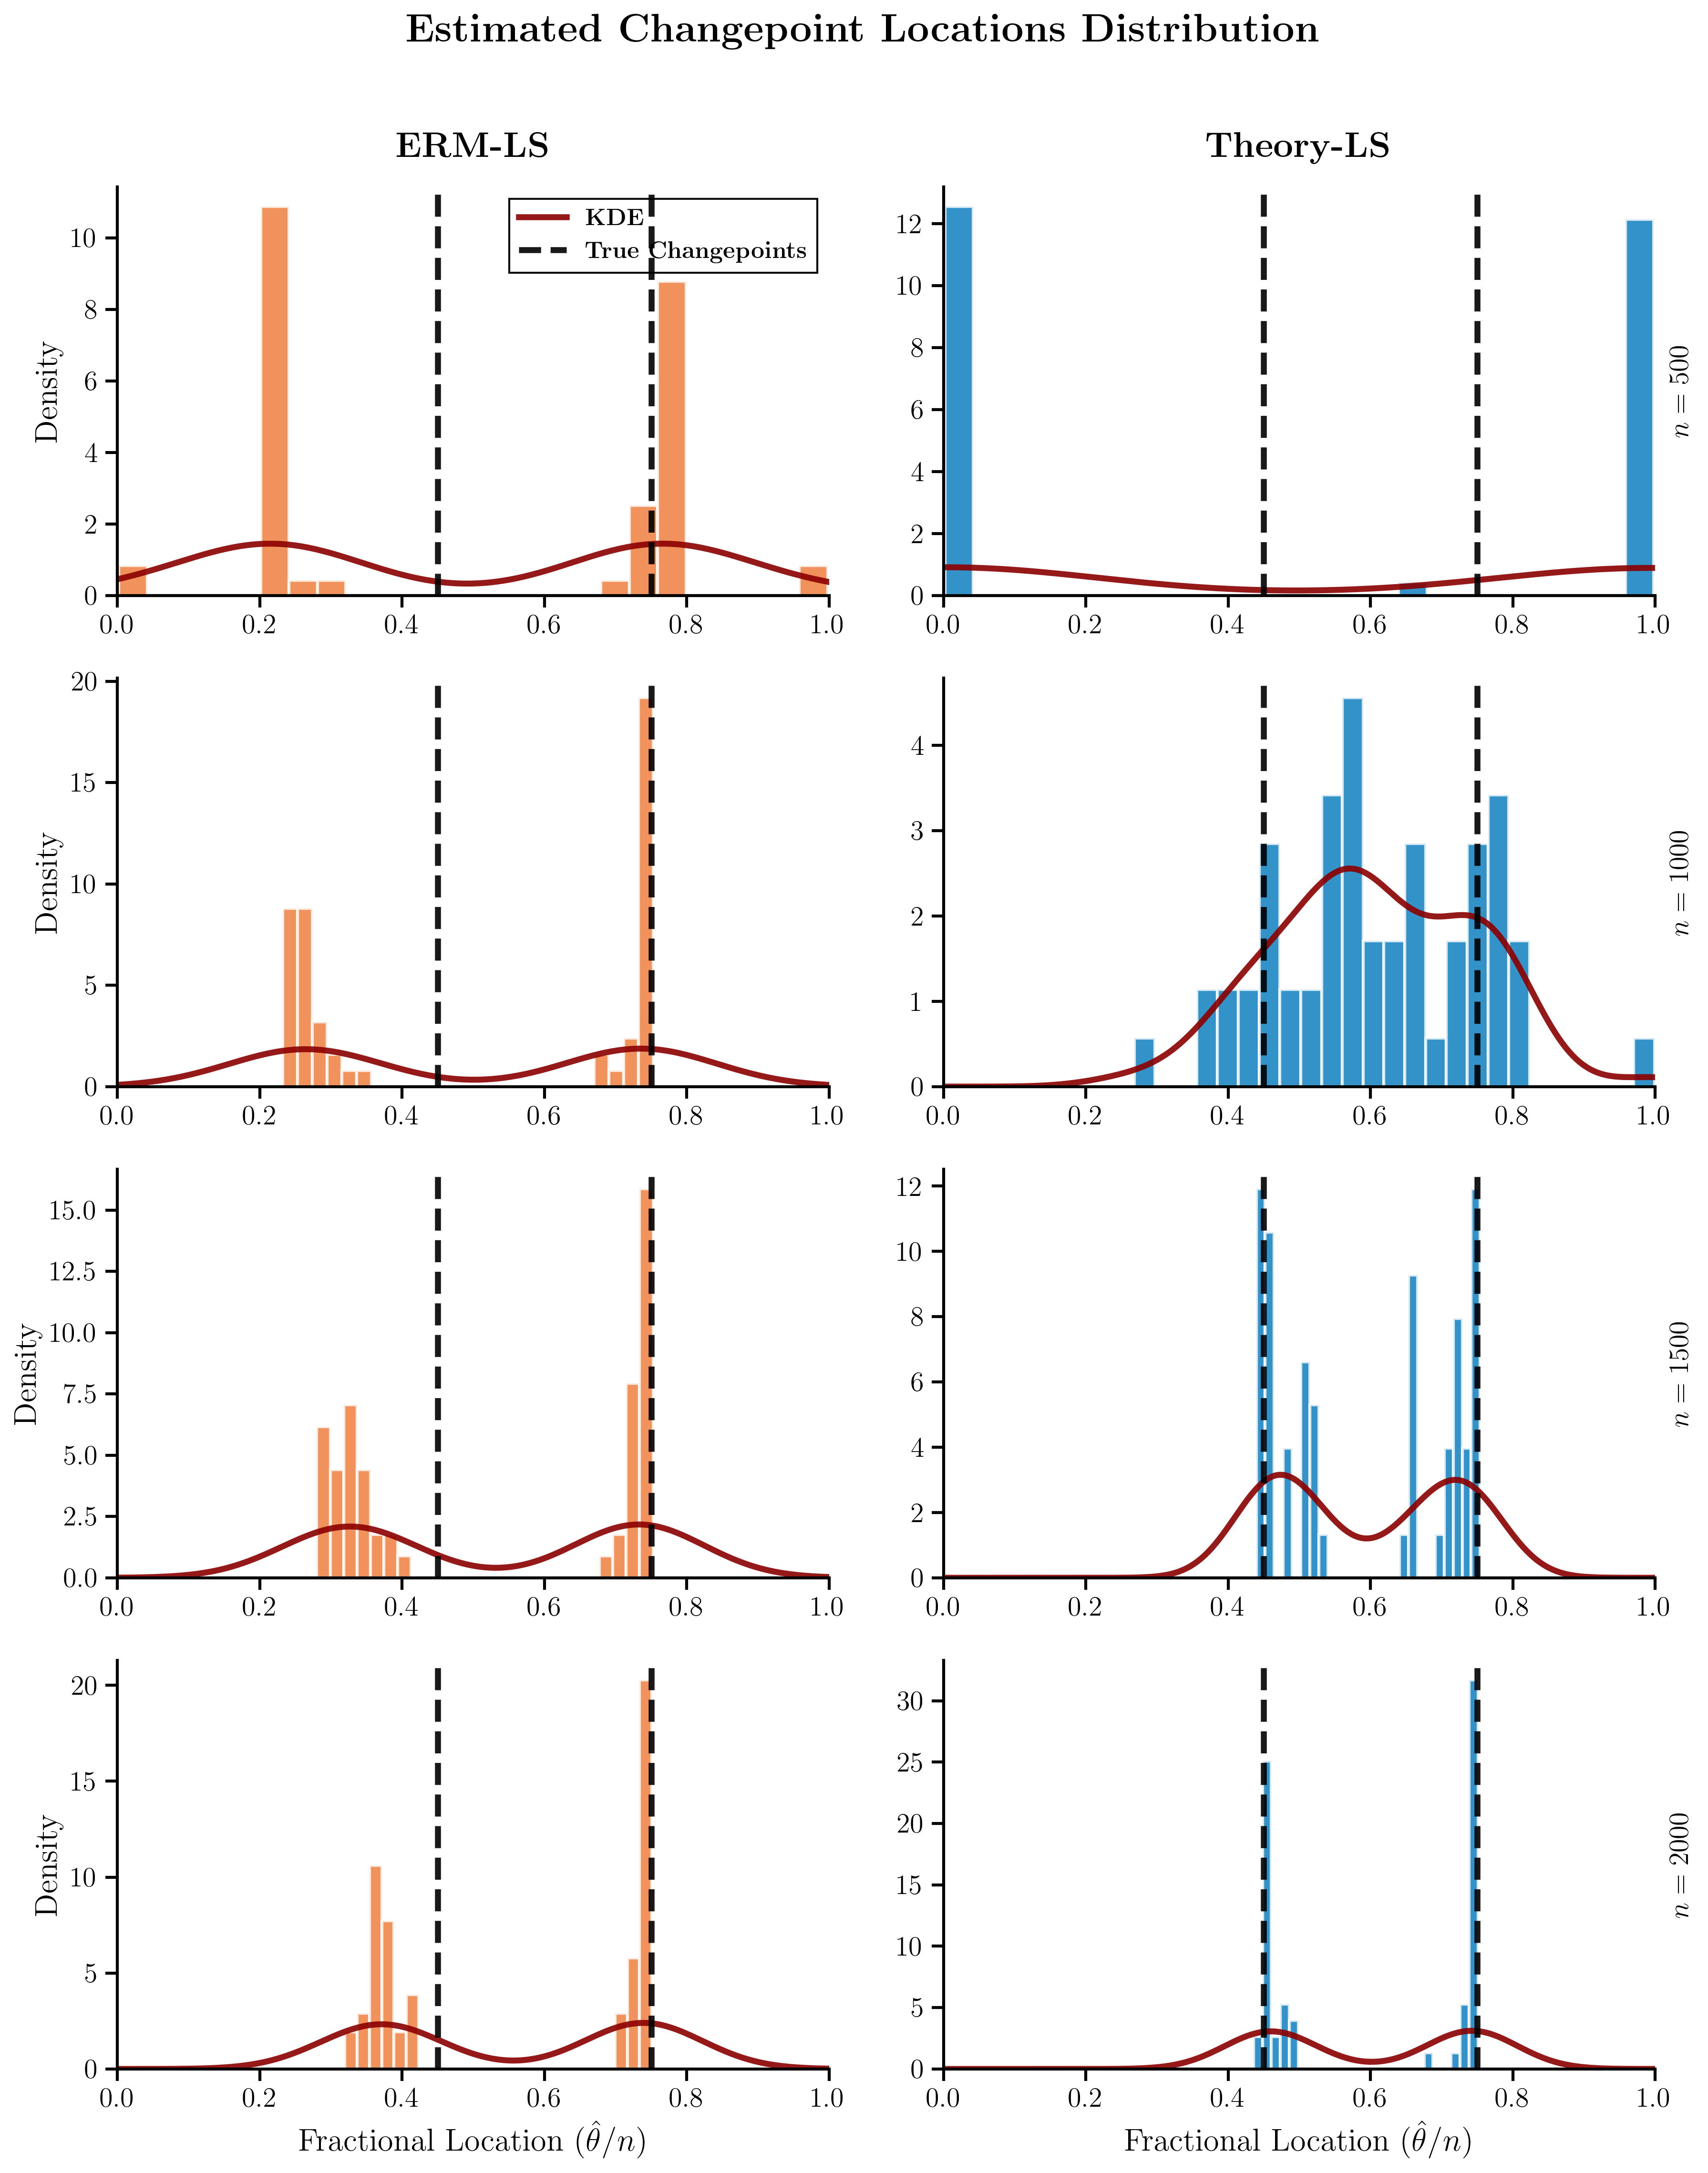

02:07:38 - Publication-ready plotting completed in 2.92 seconds


NameError: name 'os' is not defined

Search complete. Optimal GoF score: 1780.9096
Search complete. Optimal GoF score: 1666.7553
Search complete. Optimal GoF score: 1647.7881


In [ ]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Publication-Ready Asymmetric Error Bars Plots ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Increased columns for all 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis}', fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Metrics to plot
    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for i, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                # For correlation and MSE, average over the L signals first
                data = np.nanmean(data, axis=2) # Average across L signals
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(δ_list, means, yerr=errors,
                        label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                        color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        
        if ylim:
            ax.set_ylim(ylim)
        else: # For MSE and Runtime, ensure y-axis starts at 0
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Confidence Bands Plots ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(r'\textbf{WERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}', None),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}', (0, 0.5)),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}', (0, L + 2))
    ]

    for ax_idx, (metric_key, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric_key}_{method_name}']
            if metric_key in ['corr', 'mse']:
                data = np.nanmean(data, axis=2)
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means) # Ensure band doesn't go above mean for lower bound
            p90 = np.maximum(p90, means) # Ensure band doesn't go below mean for upper bound

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric_key in ['mse', 'runtime']:
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate) + (1 if 'size' in [m[0] for m in metrics] else 0),
               fontsize=16, frameon=True, edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 4, figsize=(24, 6)) # Adjusted for 4 metrics
    fig.suptitle(r'\textbf{WERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [
        ('corr', r'Normalized Squared Correlation', r'\textbf{(a) Signal Estimation: Norm Sq Corr}'),
        ('mse', r'Mean Squared Error', r'\textbf{(b) Signal Estimation: MSE}'),
        ('haus', r'Hausdorff Distance / $n$', r'\textbf{(c) Changepoint Location Error}'),
        ('size', r'Number of Changepoints', r'\textbf{(d) Changepoint Set Size}')
    ]

    for ax_idx, (metric_key, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                if metric_key in ['corr', 'mse']:
                    # Take nanmean across L signals for corr/mse before plotting
                    data_flattened = np.nanmean(data, axis=1) # Results in a 1D array per trial
                else:
                    data_flattened = data

                valid_data = data_flattened[~np.isnan(data_flattened)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                        for i in range(len(methods_to_evaluate))]
        if metric_key == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
            legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label=r'\textbf{True Size}'))

        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8: # Only plot KDE if enough samples
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            # Find the true changepoints for the current delta_idx
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            
            if current_true_chgpts is not None and len(current_true_chgpts) > 0:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or (current_true_chgpts is not None and len(current_true_chgpts) > 0)):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
main_logger.info("Generating plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/WERM_SE_match_est_switching_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"

# Create results directory if it doesn't exist
results_dir = 'results'
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)
main_logger.info(f"Results saved to {filename}")